<a href="https://colab.research.google.com/github/FatimaZahraBoukab/DeepLearning-Lab1/blob/main/Lab1_DeepLearning_PyTorch.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [2]:
!pip install -q skorch imbalanced-learn kagglehub

In [3]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import torch
import torch.nn as nn
import torch.optim as optim
from sklearn.model_selection import train_test_split, GridSearchCV
from sklearn.preprocessing import StandardScaler, LabelEncoder
from sklearn.metrics import (accuracy_score, f1_score, recall_score,
                             precision_score, confusion_matrix,
                             classification_report, r2_score,
                             mean_squared_error, mean_absolute_error)
from skorch import NeuralNetRegressor, NeuralNetClassifier

device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print("Device :", device)
torch.manual_seed(42); np.random.seed(42)

Device : cuda


In [4]:
import kagglehub
path = kagglehub.dataset_download("dgawlik/nyse")
print(path)
import os
print(os.listdir(path))

Using Colab cache for faster access to the 'nyse' dataset.
/kaggle/input/nyse
['prices-split-adjusted.csv', 'fundamentals.csv', 'prices.csv', 'securities.csv']


In [5]:
df = pd.read_csv(os.path.join(path, "prices-split-adjusted.csv"))
df['date'] = pd.to_datetime(df['date'])
df.head()

,date,symbol,open,close,low,high,volume
0,2016-01-05,WLTW,123.430000,125.839996,122.309998,126.250000,2163600.0
1,2016-01-06,WLTW,125.239998,119.980003,119.940002,125.540001,2386400.0
2,2016-01-07,WLTW,116.379997,114.949997,114.930000,119.739998,2489500.0
3,2016-01-08,WLTW,115.480003,116.620003,113.500000,117.440002,2006300.0
4,2016-01-11,WLTW,117.010002,114.970001,114.089996,117.330002,1408600.0


In [6]:
print(df.shape)
df.info()
display(df.describe())
print("Valeurs manquantes :\n", df.isnull().sum())
print("Nombre d'actions :", df['symbol'].nunique())

(851264, 7)
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 851264 entries, 0 to 851263
Data columns (total 7 columns):
 #   Column  Non-Null Count   Dtype         
---  ------  --------------   -----         
 0   date    851264 non-null  datetime64[ns]
 1   symbol  851264 non-null  object        
 2   open    851264 non-null  float64       
 3   close   851264 non-null  float64       
 4   low     851264 non-null  float64       
 5   high    851264 non-null  float64       
 6   volume  851264 non-null  float64       
dtypes: datetime64[ns](1), float64(5), object(1)
memory usage: 45.5+ MB


,date,open,close,low,high,volume
count,851264,851264.000000,851264.000000,851264.000000,851264.000000,8.512640e+05
mean,2013-07-21 02:56:29.294037760,64.993618,65.011913,64.336541,65.639748,5.415113e+06
min,2010-01-04 00:00:00,1.660000,1.590000,1.500000,1.810000,0.000000e+00
25%,2011-10-19 00:00:00,31.270000,31.292776,30.940001,31.620001,1.221500e+06
50%,2013-08-02 00:00:00,48.459999,48.480000,47.970001,48.959999,2.476250e+06
75%,2015-04-24 00:00:00,75.120003,75.139999,74.400002,75.849998,5.222500e+06
max,2016-12-30 00:00:00,1584.439941,1578.130005,1549.939941,1600.930054,8.596434e+08
std,NaN,75.203893,75.201216,74.459518,75.906861,1.249468e+07


Valeurs manquantes :
 date      0
symbol    0
open      0
close     0
low       0
high      0
volume    0
dtype: int64
Nombre d'actions : 501


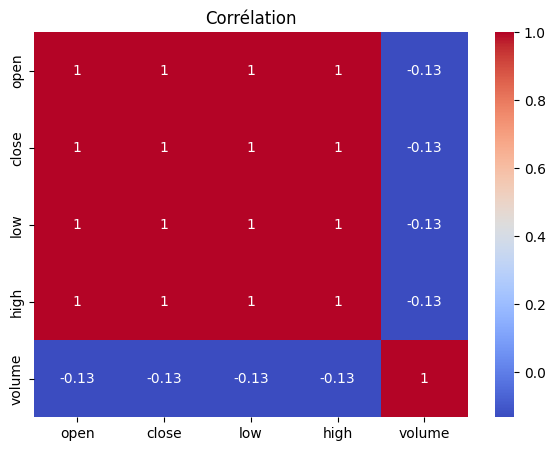

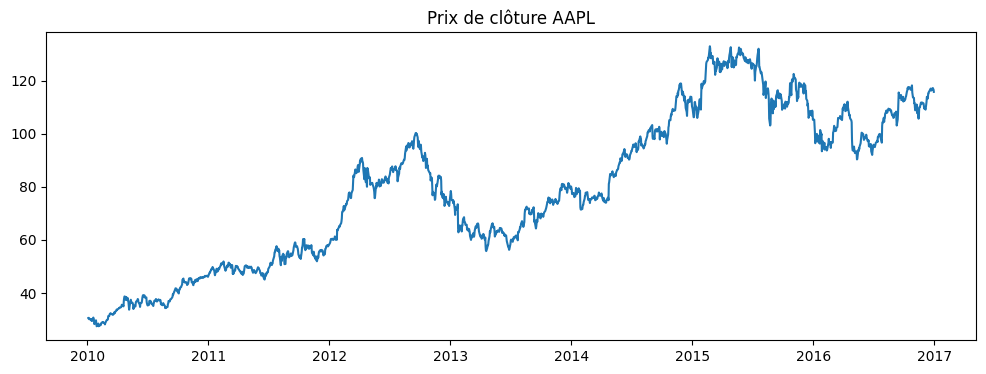

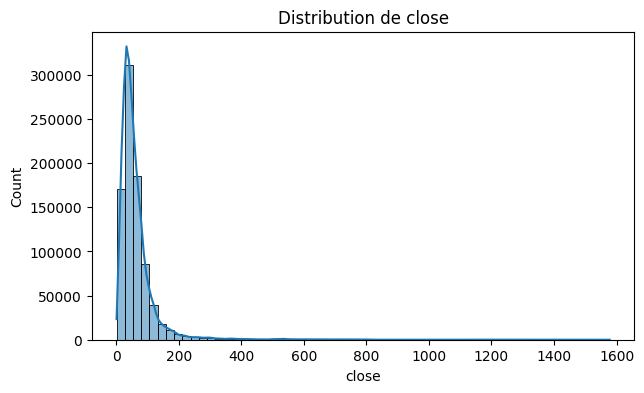

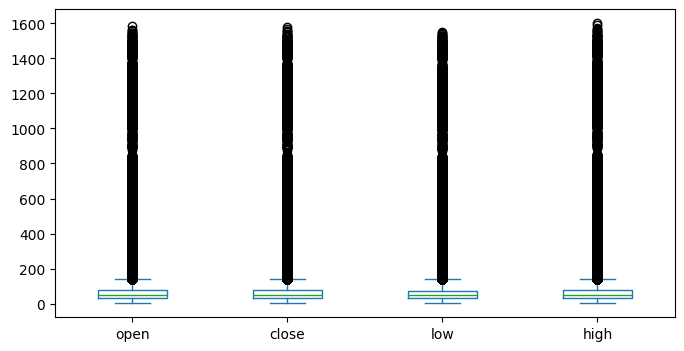

In [7]:
# Matrice de corrélation
plt.figure(figsize=(7,5))
sns.heatmap(df[['open','close','low','high','volume']].corr(), annot=True, cmap='coolwarm')
plt.title("Corrélation"); plt.show()

# Évolution d'une action (ex. AAPL)
aapl = df[df.symbol=='AAPL']
plt.figure(figsize=(12,4)); plt.plot(aapl['date'], aapl['close'])
plt.title("Prix de clôture AAPL"); plt.show()

# Distribution du prix de clôture
plt.figure(figsize=(7,4)); sns.histplot(df['close'], bins=60, kde=True)
plt.title("Distribution de close"); plt.show()

# Boxplots (valeurs aberrantes)
df[['open','close','low','high']].plot(kind='box', figsize=(8,4)); plt.show()

In [8]:
features = ['open','low','high','volume']
target = 'close'

# Pour éviter un entraînement trop lent, on peut échantillonner
data = df.sample(200000, random_state=42)

X = data[features].values.astype(np.float32)
y = data[target].values.astype(np.float32).reshape(-1,1)

X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)

sx, sy = StandardScaler(), StandardScaler()
X_train = sx.fit_transform(X_train).astype(np.float32)
X_test  = sx.transform(X_test).astype(np.float32)
y_train = sy.fit_transform(y_train).astype(np.float32)
y_test  = sy.transform(y_test).astype(np.float32)

In [9]:
class MLPReg(nn.Module):
    def __init__(self, n_in=4, h1=64, h2=32, dropout=0.0):
        super().__init__()
        self.net = nn.Sequential(
            nn.Linear(n_in, h1), nn.ReLU(), nn.Dropout(dropout),
            nn.Linear(h1, h2), nn.ReLU(), nn.Dropout(dropout),
            nn.Linear(h2, 1)
        )
    def forward(self, x):
        return self.net(x)

In [10]:
# Sous-échantillon pour le GridSearch uniquement
X_small = X_train[:40000]
y_small = y_train[:40000]

net = NeuralNetRegressor(
    MLPReg,
    criterion=nn.MSELoss,
    optimizer=optim.Adam,
    max_epochs=20,
    batch_size=1024,
    train_split=None,
    device=device,
    verbose=0,
)

params = {
    'lr': [0.001, 0.01],
    'optimizer': [optim.Adam, optim.SGD],
    'max_epochs': [20, 40],
    'module__h1': [32, 64],
    'module__h2': [32],
}

gs = GridSearchCV(net, params, cv=2, scoring='r2', n_jobs=1, verbose=1)
gs.fit(X_small, y_small)
print("Meilleurs paramètres :", gs.best_params_)
print("Meilleur R2 CV :", gs.best_score_)

Fitting 2 folds for each of 16 candidates, totalling 32 fits
Meilleurs paramètres : {'lr': 0.001, 'max_epochs': 40, 'module__h1': 32, 'module__h2': 32, 'optimizer': <class 'torch.optim.adam.Adam'>}
Meilleur R2 CV : 0.9998336732387543


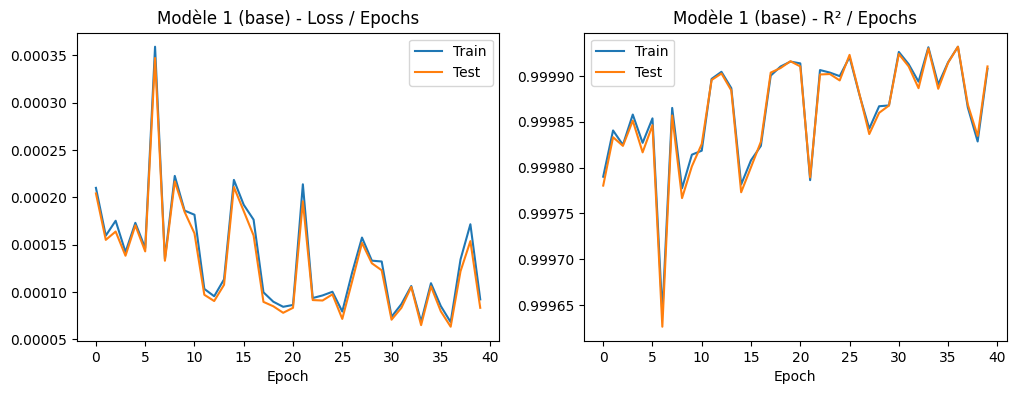

R2 train : 0.9999078424608104
R2 test  : 0.9999103730324387


In [11]:
bp = gs.best_params_

def train_reg(model, lr, opt_class, epochs, wd=0.0, patience=None):
    model = model.to(device)
    opt = opt_class(model.parameters(), lr=lr, weight_decay=wd)
    loss_fn = nn.MSELoss()
    Xtr = torch.tensor(X_train).to(device); ytr = torch.tensor(y_train).to(device)
    Xte = torch.tensor(X_test).to(device);  yte = torch.tensor(y_test).to(device)
    hist = {'train_loss': [], 'test_loss': [], 'train_r2': [], 'test_r2': []}
    best, wait = 1e9, 0
    for ep in range(epochs):
        model.train()
        perm = torch.randperm(len(Xtr))
        for i in range(0, len(Xtr), 256):
            idx = perm[i:i+256]
            opt.zero_grad()
            loss = loss_fn(model(Xtr[idx]), ytr[idx])
            loss.backward()
            opt.step()
        model.eval()
        with torch.no_grad():
            ptr, pte = model(Xtr), model(Xte)
            ltr, lte = loss_fn(ptr, ytr).item(), loss_fn(pte, yte).item()
            hist['train_loss'].append(ltr); hist['test_loss'].append(lte)
            hist['train_r2'].append(r2_score(ytr.cpu(), ptr.cpu()))
            hist['test_r2'].append(r2_score(yte.cpu(), pte.cpu()))
        if patience:
            if lte < best:
                best, wait = lte, 0
            else:
                wait += 1
                if wait >= patience:
                    break
    return model, hist

def plot_hist(h, title):
    fig, ax = plt.subplots(1, 2, figsize=(12, 4))
    ax[0].plot(h['train_loss'], label='Train'); ax[0].plot(h['test_loss'], label='Test')
    ax[0].set_title(f'{title} - Loss / Epochs'); ax[0].set_xlabel('Epoch'); ax[0].legend()
    ax[1].plot(h['train_r2'], label='Train'); ax[1].plot(h['test_r2'], label='Test')
    ax[1].set_title(f'{title} - R² / Epochs'); ax[1].set_xlabel('Epoch'); ax[1].legend()
    plt.show()

m1 = MLPReg(4, bp['module__h1'], bp['module__h2'])
m1, h1 = train_reg(m1, bp['lr'], bp['optimizer'], bp['max_epochs'])
plot_hist(h1, "Modèle 1 (base)")
print("R2 train :", h1['train_r2'][-1])
print("R2 test  :", h1['test_r2'][-1])

In [12]:
class MLPRegReg(nn.Module):
    def __init__(self, n_in=4, h1=32, h2=32, dropout=0.0, batchnorm=False):
        super().__init__()
        layers = [nn.Linear(n_in, h1)]
        if batchnorm: layers.append(nn.BatchNorm1d(h1))
        layers += [nn.ReLU(), nn.Dropout(dropout), nn.Linear(h1, h2)]
        if batchnorm: layers.append(nn.BatchNorm1d(h2))
        layers += [nn.ReLU(), nn.Dropout(dropout), nn.Linear(h2, 1)]
        self.net = nn.Sequential(*layers)
    def forward(self, x):
        return self.net(x)

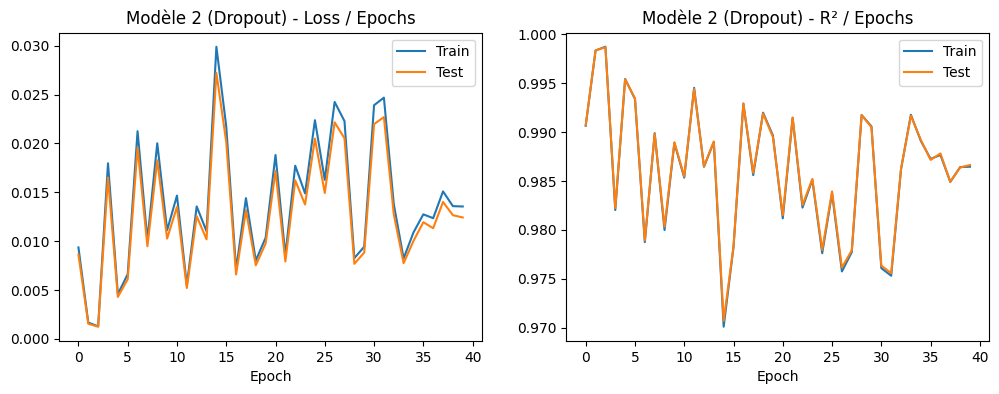

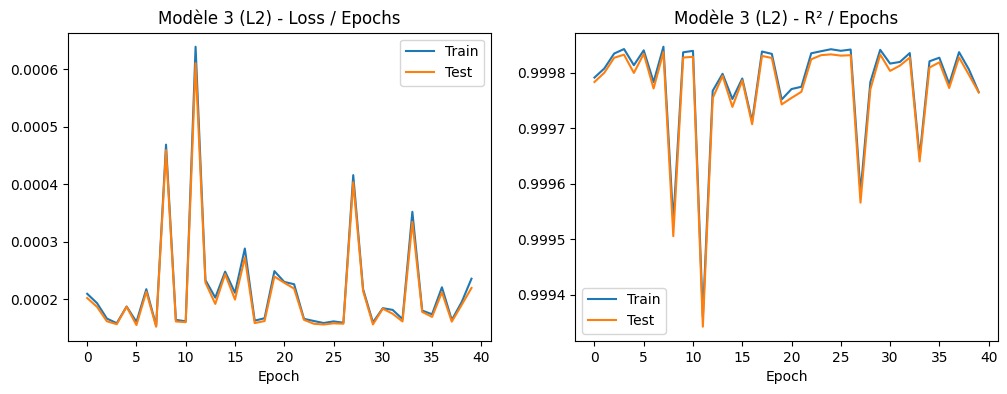

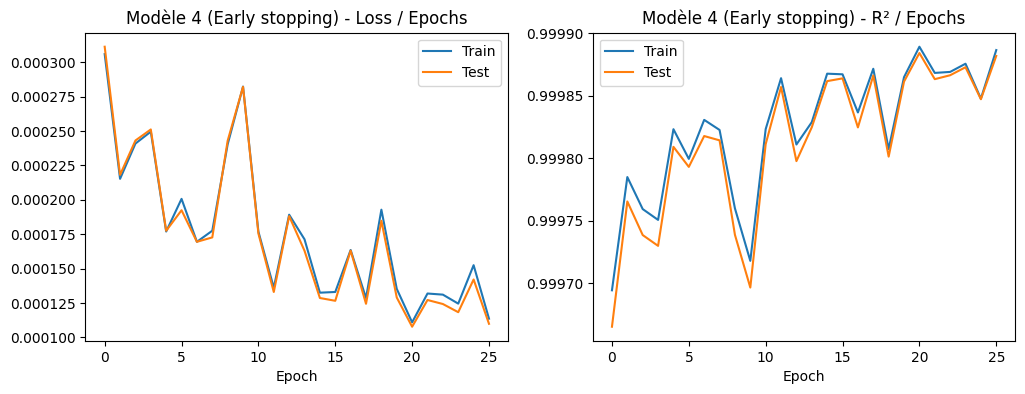

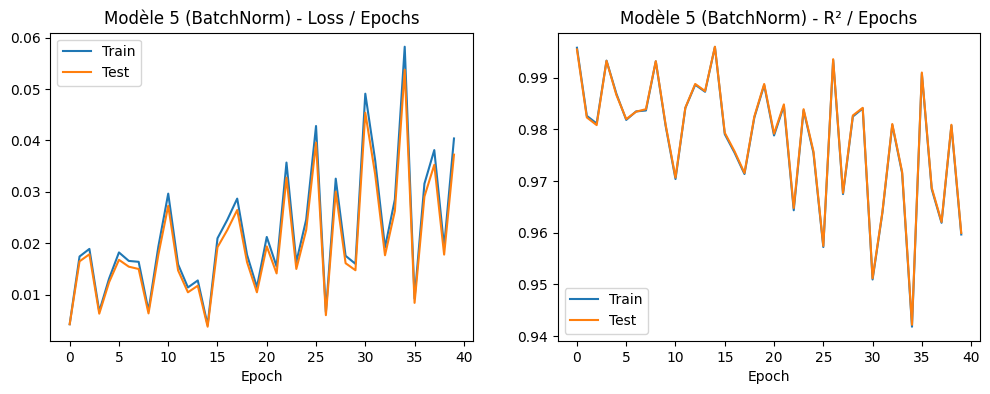

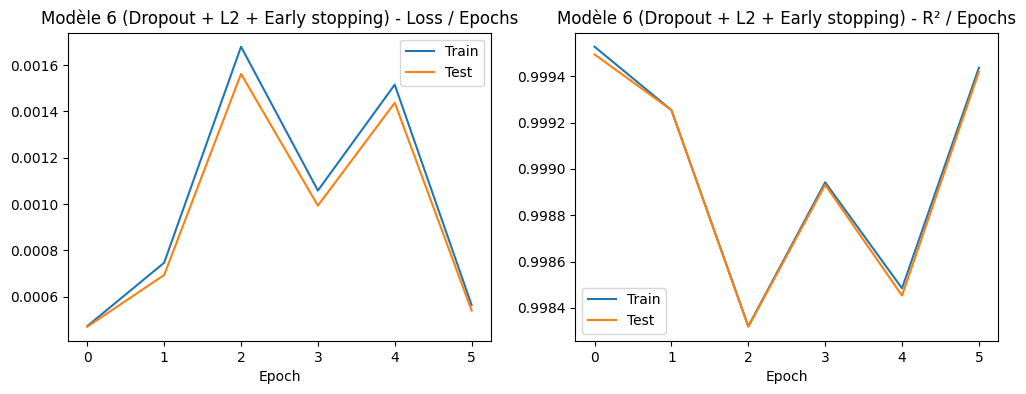

In [13]:
h1_, h2_ = bp['module__h1'], bp['module__h2']
lr, opt_c, ep = bp['lr'], bp['optimizer'], bp['max_epochs']

# Modèle 2 : Dropout seul
m2, hist2 = train_reg(MLPRegReg(4, h1_, h2_, dropout=0.2), lr, opt_c, ep)

# Modèle 3 : L2 (weight decay) seul
m3, hist3 = train_reg(MLPRegReg(4, h1_, h2_), lr, opt_c, ep, wd=1e-3)

# Modèle 4 : Early stopping seul
m4, hist4 = train_reg(MLPRegReg(4, h1_, h2_), lr, opt_c, 100, patience=5)

# Modèle 5 : BatchNorm seule
m5, hist5 = train_reg(MLPRegReg(4, h1_, h2_, batchnorm=True), lr, opt_c, ep)

# Modèle 6 : Combinaison Dropout + L2 + Early stopping
m6, hist6 = train_reg(MLPRegReg(4, h1_, h2_, dropout=0.1), lr, opt_c, 100, wd=1e-4, patience=5)

plot_hist(hist2, "Modèle 2 (Dropout)")
plot_hist(hist3, "Modèle 3 (L2)")
plot_hist(hist4, "Modèle 4 (Early stopping)")
plot_hist(hist5, "Modèle 5 (BatchNorm)")
plot_hist(hist6, "Modèle 6 (Dropout + L2 + Early stopping)")

,Modèle,Epochs,Loss train,Loss test,R² train,R² test,Écart R² (train-test)
0,Base (modèle 1),40,0.000092,0.000083,0.999908,0.999910,-0.000003
1,Dropout,40,0.013549,0.012426,0.986451,0.986625,-0.000174
2,L2,40,0.000235,0.000219,0.999765,0.999764,0.000001
3,Early stopping,26,0.000114,0.000110,0.999886,0.999882,0.000005
4,BatchNorm,40,0.040370,0.037222,0.959630,0.959936,-0.000306
5,Combiné,6,0.000564,0.000540,0.999436,0.999419,0.000017


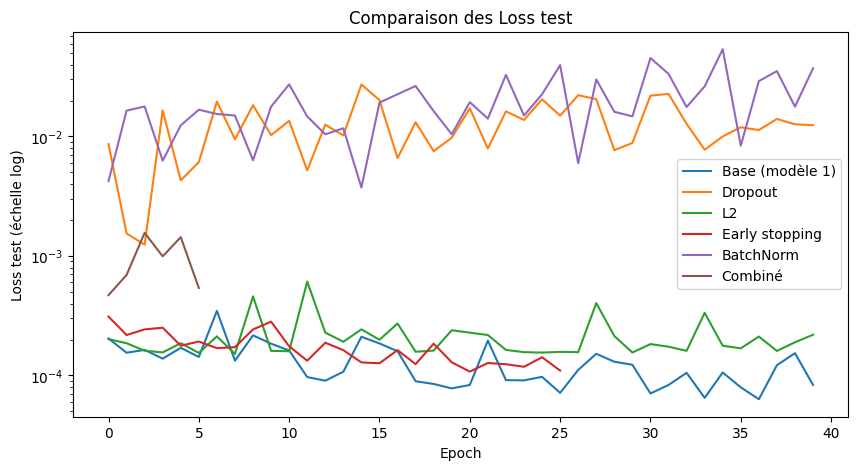

In [14]:
histories = {
    'Base (modèle 1)': h1,
    'Dropout': hist2,
    'L2': hist3,
    'Early stopping': hist4,
    'BatchNorm': hist5,
    'Combiné': hist6,
}

rows = []
for name, h in histories.items():
    rows.append({
        'Modèle': name,
        'Epochs': len(h['train_loss']),
        'Loss train': h['train_loss'][-1],
        'Loss test': h['test_loss'][-1],
        'R² train': h['train_r2'][-1],
        'R² test': h['test_r2'][-1],
        'Écart R² (train-test)': h['train_r2'][-1] - h['test_r2'][-1],
    })
comparaison = pd.DataFrame(rows).round(6)
display(comparaison)

plt.figure(figsize=(10, 5))
for name, h in histories.items():
    plt.plot(h['test_loss'], label=name)
plt.yscale('log')
plt.xlabel('Epoch'); plt.ylabel('Loss test (échelle log)')
plt.title('Comparaison des Loss test'); plt.legend(); plt.show()